## Exploratory Data Analysis Summary

This notebook examined the combined student and Reddit datasets.

Key observations:

1. The combined dataset contains 70,288 records: 42,387 Reddit records and 27,901 Student records.
2. Both sources contain records from the two binary classes: non-depression (0) and depression-related (1).
3. Average text length differs between sources. Student records contain approximately 26 words, while Reddit records contain approximately 105 words.
4. Word clouds provide a visual comparison of frequently occurring terms across the two classes.
5. Correlation analysis of selected student features revealed mostly weak linear relationships.

### Important limitation

The Student and Reddit records originate from separate datasets. Their text characteristics and collection processes differ. These exploratory findings should not be interpreted as evidence of clinical relationships or diagnostic validity.

In [1]:
# IMPORT DEPENDENCIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
import nltk
from nltk.corpus import stopwords
import re

In [2]:
# Download NLTK resources (run once)
nltk.download('stopwords')

# Load the verified combined dataset
df = pd.read_csv('../data/processed/combined_hybrid_student_reddit_data.csv')

# Verify the existing source labels
print("Total Records:", len(df))

print("\nSource Distribution:")
print(df['source'].value_counts())

print("\nDataset Preview:")
display(df.head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\NUGGET\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Total Records: 70288

Source Distribution:
source
Reddit     42387
Student    27901
Name: count, dtype: int64

Dataset Preview:


,clean_text,binary_label,source
0,"at this hour i just woke up, even though yeste...",0,Reddit
1,"A 22-year-old Male student with CGPA 3.39, 4.0...",1,Student
2,"A 27-year-old Female student with CGPA 2.94, 5...",1,Student
3,"A 28-year-old Female student with CGPA 3.44, 1...",0,Student
4,"A 32-year-old Female student with CGPA 2.92, 4...",1,Student


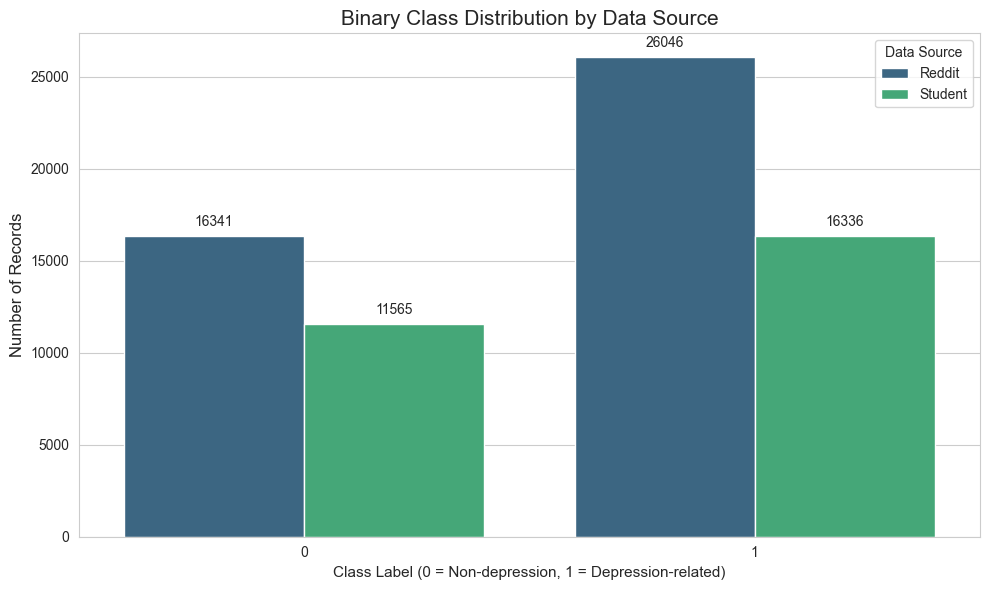

In [5]:
# Set visual style
sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    x='binary_label',
    data=df,
    hue='source',
    palette='viridis'
)

plt.title('Binary Class Distribution by Data Source', fontsize=15)
plt.xlabel('Class Label (0 = Non-depression, 1 = Depression-related)', fontsize=11)
plt.ylabel('Number of Records', fontsize=12)
plt.legend(title='Data Source')

# Display counts above the bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(
            f'{int(p.get_height())}',
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center',
            va='bottom',
            xytext=(0, 5),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

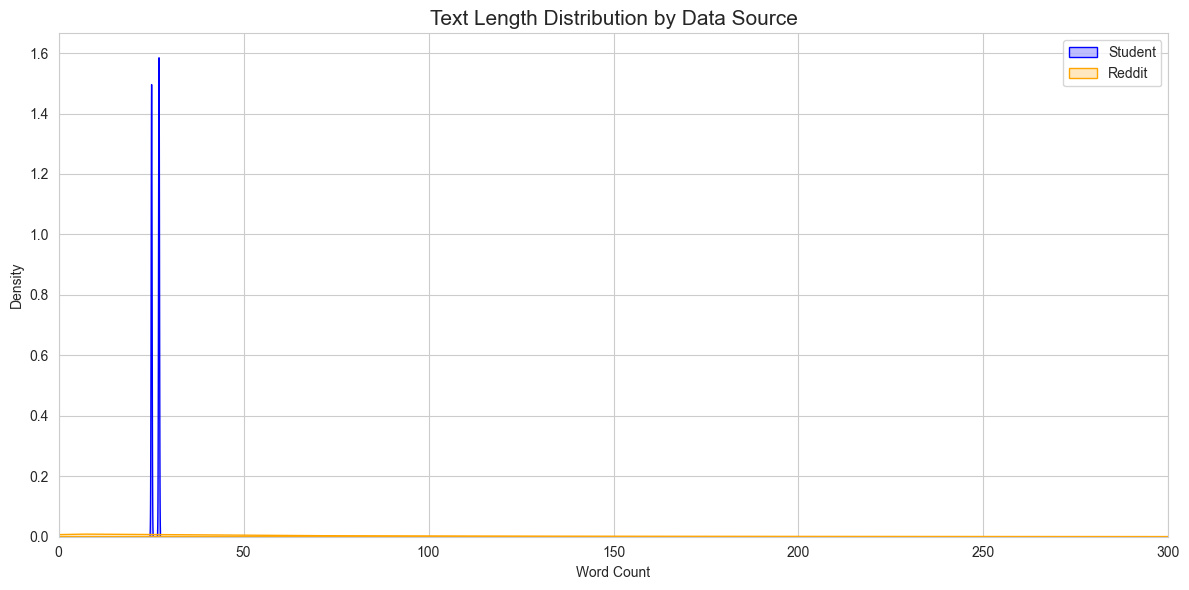

Average Word Count (Student): 26.028278556324146
Average Word Count (Reddit): 104.50406964399463


In [6]:
# Calculate the number of words in each text record
df['word_count'] = df['clean_text'].apply(
    lambda x: len(str(x).split())
)

plt.figure(figsize=(12, 6))

# Compare text lengths by data source
sns.kdeplot(
    data=df[df['source'] == 'Student'],
    x='word_count',
    fill=True,
    label='Student',
    color='blue'
)

sns.kdeplot(
    data=df[df['source'] == 'Reddit'],
    x='word_count',
    fill=True,
    label='Reddit',
    color='orange'
)

plt.title('Text Length Distribution by Data Source', fontsize=15)
plt.xlabel('Word Count')
plt.ylabel('Density')
plt.xlim(0, 300)
plt.legend()

plt.tight_layout()
plt.show()

# Display average text length
print(
    "Average Word Count (Student):",
    df[df['source'] == 'Student']['word_count'].mean()
)

print(
    "Average Word Count (Reddit):",
    df[df['source'] == 'Reddit']['word_count'].mean()
)

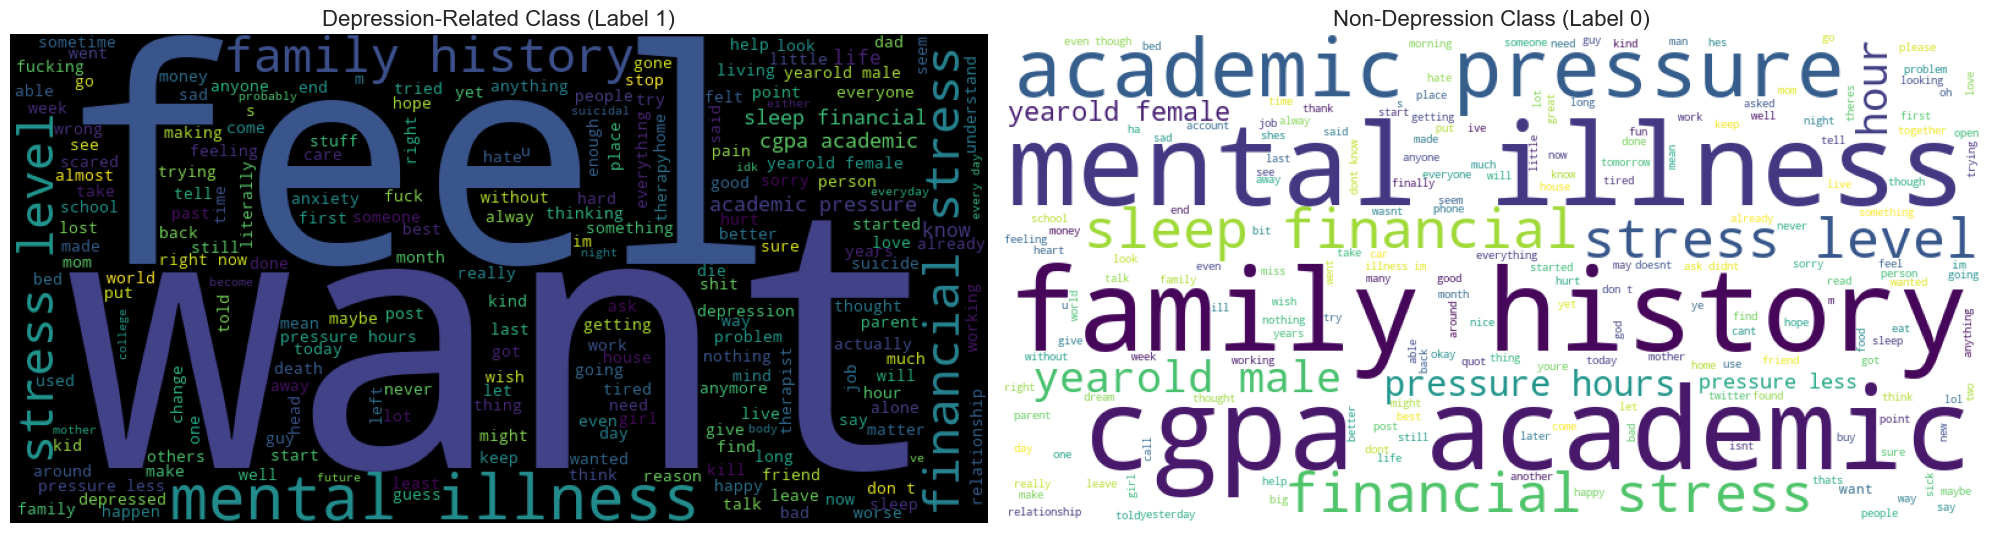

In [7]:
# Clean text for word cloud visualization
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

# Separate text by binary class
depression_related_text = " ".join(
    df[df['binary_label'] == 1]['clean_text'].apply(clean_text)
)

non_depression_text = " ".join(
    df[df['binary_label'] == 0]['clean_text'].apply(clean_text)
)

# Define stopwords
custom_stops = set(STOPWORDS)
custom_stops.update([
    'subject', 'student', 'year', 'old',
    'reports', 'wa'
])

# Generate word clouds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

wordcloud1 = WordCloud(
    width=800,
    height=400,
    background_color='black',
    stopwords=custom_stops
).generate(depression_related_text)

ax1.imshow(wordcloud1)
ax1.set_title('Depression-Related Class (Label 1)', fontsize=16)
ax1.axis('off')

wordcloud2 = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=custom_stops
).generate(non_depression_text)

ax2.imshow(wordcloud2)
ax2.set_title('Non-Depression Class (Label 0)', fontsize=16)
ax2.axis('off')

plt.tight_layout()
plt.show()

,Academic Pressure,Work Pressure,CGPA,Financial Stress
Academic Pressure,1.000000,-0.022231,-0.022239,0.151706
Work Pressure,-0.022231,1.000000,-0.050896,0.001883
CGPA,-0.022239,-0.050896,1.000000,0.005885
Financial Stress,0.151706,0.001883,0.005885,1.000000


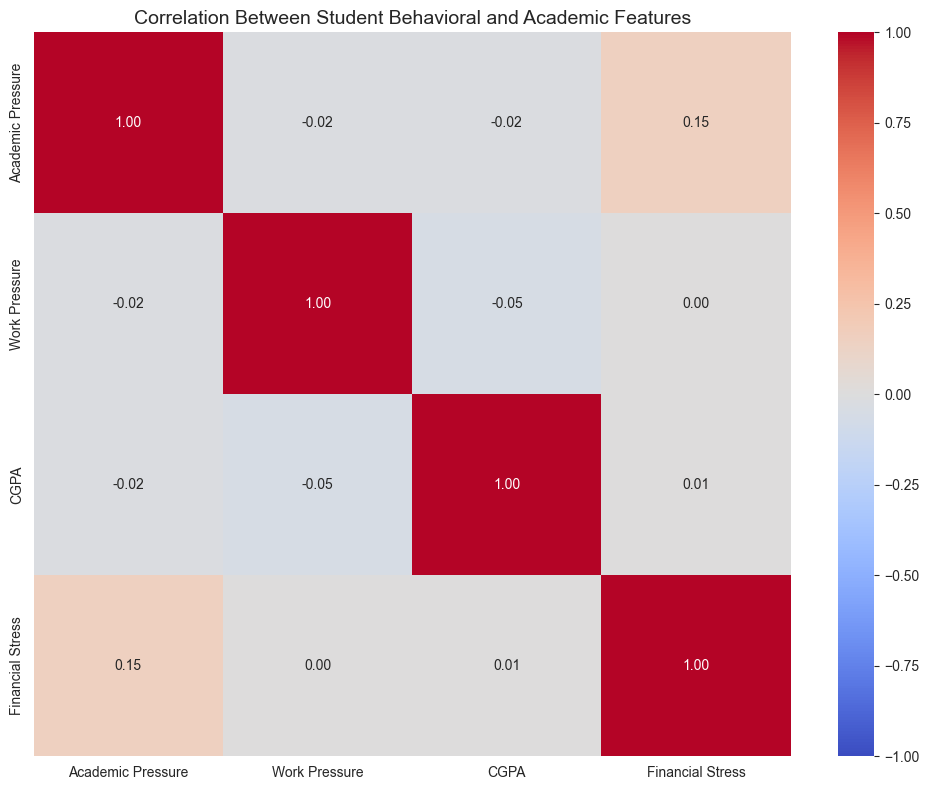

In [8]:
# Load the original student dataset
student_raw = pd.read_csv(
    '../data/raw/student_depression_dataset.csv'
)

# Select numerical features for correlation analysis
numeric_cols = [
    'Academic Pressure',
    'Work Pressure',
    'CGPA',
    'Financial Stress'
]

# Convert values to numeric, treating '?' as missing
for col in numeric_cols:
    student_raw[col] = pd.to_numeric(
        student_raw[col].replace('?', np.nan),
        errors='coerce'
    )

# Calculate the correlation matrix
corr_matrix = student_raw[numeric_cols].corr()

# Display the correlation matrix
display(corr_matrix)

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title(
    'Correlation Between Student Behavioral and Academic Features',
    fontsize=14
)

plt.tight_layout()
plt.show()